In [1]:
import pandas as pd
import numpy as np
import time
from geopy.geocoders import Nominatim
import numpy as np
import math
import sklearn as skl
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import lightgbm as lgbm
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.max_columns", None)

In [43]:
df = pd.read_csv("../information_about_flats_with_coordinates.csv")

C:\Users\Davidka\AppData\Local\Temp\ipykernel_6504\1308135404.py:1: DtypeWarning: Columns (0: комнат в квартире) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../information_about_flats_with_coordinates.csv")


In [44]:
for clm in df.columns:
    if np.sum(df[[clm]].isnull())/df.shape[0] >= 0.35:
        df.drop(clm, axis=1, inplace=True)

In [6]:
geolocator = Nominatim(user_agent="flat_app")
locat_longitude = []
locat_latitide = []
i = 0
while i != len(df["адрес"]):
    try:
        address = df["адрес"][i]
        address_details = address.split(",")
        location = geolocator.geocode(f"москва, {address_details[-2]}, {address_details[-1]}")
        if location is not None:
            locat_latitide.append(location.latitude)
            locat_longitude.append(location.longitude)
        else:
            locat_latitide.append(None)
            locat_longitude.append(None)
        if i % 100 == 0:
            print(i)
        i += 1
        time.sleep(1)
    except Exception as e:
        time.sleep(5)
        pass


0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600


In [10]:
df.insert(len(df.columns), "долгота", locat_longitude)
df.insert(len(df.columns), "широта", locat_latitide)

df.drop("адрес", axis=1, inplace=True)
df.to_csv("information_about_flats_notebook_coordinates.csv", index_label=False)

In [4]:
df.reset_index(inplace=True, drop=True)

In [45]:
for clm in ["общая площадь", "площадь кухни", "высота потолков", "жилая площадь"]:
    new_values = []
    for item in df[clm]:
        if isinstance(item, str):
            new_values.append(float(item.split()[0].replace(",", ".")))
        else:
            new_values.append(item)
    df[clm] = new_values

In [46]:
new_values = []
for item in df["стоимость"]:
    new_values.append(float("".join(item.split()[:-1])))

df["стоимость"] = new_values

In [47]:
# 0 - 0.15 - нижние
# 0.15 - 0.40 - ниже - среднего
# 0.40 - 0.60 - средние
# 0.60 - 0.85 - выше - среднего
# 0.85 - 1 - высокие

new_values = []
for item in df["этаж"]:
    if isinstance(item, str):
        flat_class = int(item.split()[0]) / int(item.split()[2])
        if flat_class <= 0.15:
            new_values.append("нижние")
        elif 0.15 < flat_class <= 0.40:
            new_values.append("ниже - среднего")
        elif 0.40 < flat_class <= 0.60:
            new_values.append("средние")
        elif 0.60 < flat_class <= 0.85:
            new_values.append("выше - среднего")
        else:
            new_values.append("высокие")
    else:
        new_values.append(None)

df["этаж"] = new_values

In [48]:
# 1 санузел
# 2 - 3 санузла
# больше 3
# Раздельный

new_values_toilet_class = []
new_values_sep_toilet = []
for item in df["санузел"]:
    if isinstance(item, str):
        item_split = item.split()
        if len(item_split) == 2:
            toilet_amount = int(item_split[0])
        else:
            toilet_amount = int(item_split[0]) + int(item_split[2])
        if "раздельн" in item:
            new_values_sep_toilet.append(1)
        else:
            new_values_sep_toilet.append(0)
        if toilet_amount == 1:
            new_values_toilet_class.append("1_санузел")
        elif toilet_amount <= 3:
            new_values_toilet_class.append("2_3_санузла")
        else:
            new_values_toilet_class.append("больше 3 санузла")
    else:
        new_values_toilet_class.append(None)
        new_values_sep_toilet.append(None)
df["санузел"] = new_values_toilet_class
df["раздельный_санузел"] = new_values_sep_toilet

In [49]:
list_lifts_amount = []

for i in df["количество лифтов"]:
    if isinstance(i, str):
        item_split = i.split()
        if len(item_split) == 2:
            lifts_amount = int(item_split[0])
        else:
            lifts_amount = int(item_split[0]) + int(item_split[2])
        list_lifts_amount.append(lifts_amount)

percent_1 = np.percentile(list_lifts_amount, 35)
percent_2 = np.percentile(list_lifts_amount, 65)

In [50]:
new_values_lift_class = []
new_values_bages_lift = []
for item in df["количество лифтов"]:
    if isinstance(item, str):
        item_split = item.split()
        if len(item_split) == 2:
            lifts_amount = int(item_split[0])
        else:
            lifts_amount = int(item_split[0]) + int(item_split[2])
        if "груз" in item:
            new_values_bages_lift.append(1)
        else:
            new_values_bages_lift.append(0)
        if lifts_amount <= percent_1:
            new_values_lift_class.append("немного_лифтов")
        elif percent_1 < lifts_amount <= percent_2:
            new_values_lift_class.append("среднее_кол_лифтов")
        else:
            new_values_lift_class.append("много_лифтов")
    else:
        new_values_lift_class.append(None)
        new_values_bages_lift.append(None)
df["количество лифтов"] = new_values_lift_class
df["грузовой_лифт"] = new_values_bages_lift

In [24]:
df

,стоимость,общая площадь,площадь кухни,этаж,тип жилья,высота потолков,санузел,количество лифтов,тип дома,жилая площадь,долгота,широта,раздельный_санузел,грузовой_лифт
0,10083817.0,26.40,5.0,выше - среднего,новостройка,2.73,1_санузел,среднее_кол_лифтов,монолитный,NaN,NaN,NaN,0.0,1.0
1,10000000.0,17.90,5.0,ниже - среднего,вторичка / апартаменты,2.90,1_санузел,среднее_кол_лифтов,NaN,7.9,37.709014,55.723467,0.0,1.0
2,10000000.0,57.80,12.9,средние,вторичка,2.64,1_санузел,среднее_кол_лифтов,монолитный,33.7,37.604777,55.695595,1.0,1.0
3,10032980.0,23.30,NaN,средние,новостройка / апартаменты,3.00,NaN,много_лифтов,монолитный,NaN,37.707626,55.728538,NaN,1.0
4,10000000.0,31.60,9.0,средние,вторичка,2.70,1_санузел,много_лифтов,панельный,17.0,37.303900,55.486139,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64908,60094400.0,105.80,26.1,средние,новостройка,3.25,2_3_санузла,немного_лифтов,монолитный,54.8,37.689212,55.747458,0.0,1.0
64909,60037120.0,65.60,23.8,высокие,новостройка,3.33,2_3_санузла,немного_лифтов,монолитный,29.3,NaN,NaN,0.0,1.0
64910,60031930.0,82.70,28.9,ниже - среднего,новостройка,3.07,2_3_санузла,NaN,монолитный,33.4,NaN,NaN,1.0,NaN
64911,60058043.0,124.01,NaN,средние,новостройка / апартаменты,2.95,NaN,много_лифтов,монолитный,NaN,NaN,NaN,NaN,1.0


In [74]:
df = df[df["долгота"].notna()]
df.reset_index(inplace=True, drop=True)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26529 entries, 0 to 26528
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   стоимость           26529 non-null  float64
 1   общая площадь       26529 non-null  float64
 2   площадь кухни       26529 non-null  float64
 3   этаж                26529 non-null  str    
 4   тип жилья           26529 non-null  str    
 5   высота потолков     26529 non-null  float64
 6   санузел             22938 non-null  str    
 7   количество лифтов   22580 non-null  str    
 8   тип дома            24437 non-null  str    
 9   жилая площадь       26529 non-null  float64
 10  долгота             26529 non-null  float64
 11  широта              26529 non-null  float64
 12  раздельный_санузел  22938 non-null  float64
 13  грузовой_лифт       22580 non-null  float64
dtypes: float64(9), str(5)
memory usage: 2.8 MB


In [51]:
shuffle_data = df.sample(frac=1).reset_index(drop=True)
edge = int(len(shuffle_data) * 0.7)
data_train, data_test = shuffle_data[:edge], shuffle_data[edge:]

In [52]:
category_clmns = ["санузел", "количество лифтов", "тип дома", "раздельный_санузел", "грузовой_лифт"]
contin_clmns = ["площадь кухни", "высота потолков", "жилая площадь", "долгота", "широта"]

for clm in contin_clmns:
    mean_value = np.mean(data_train[clm])
    data_train[clm] = data_train[clm].fillna(mean_value)
    data_test[clm] = data_test[clm].fillna(mean_value)

for clm in category_clmns:
    moda_value = data_train[clm].mode()[0]
    data_train[clm] = data_train[clm].fillna(moda_value)
    data_test[clm] = data_test[clm].fillna(moda_value)

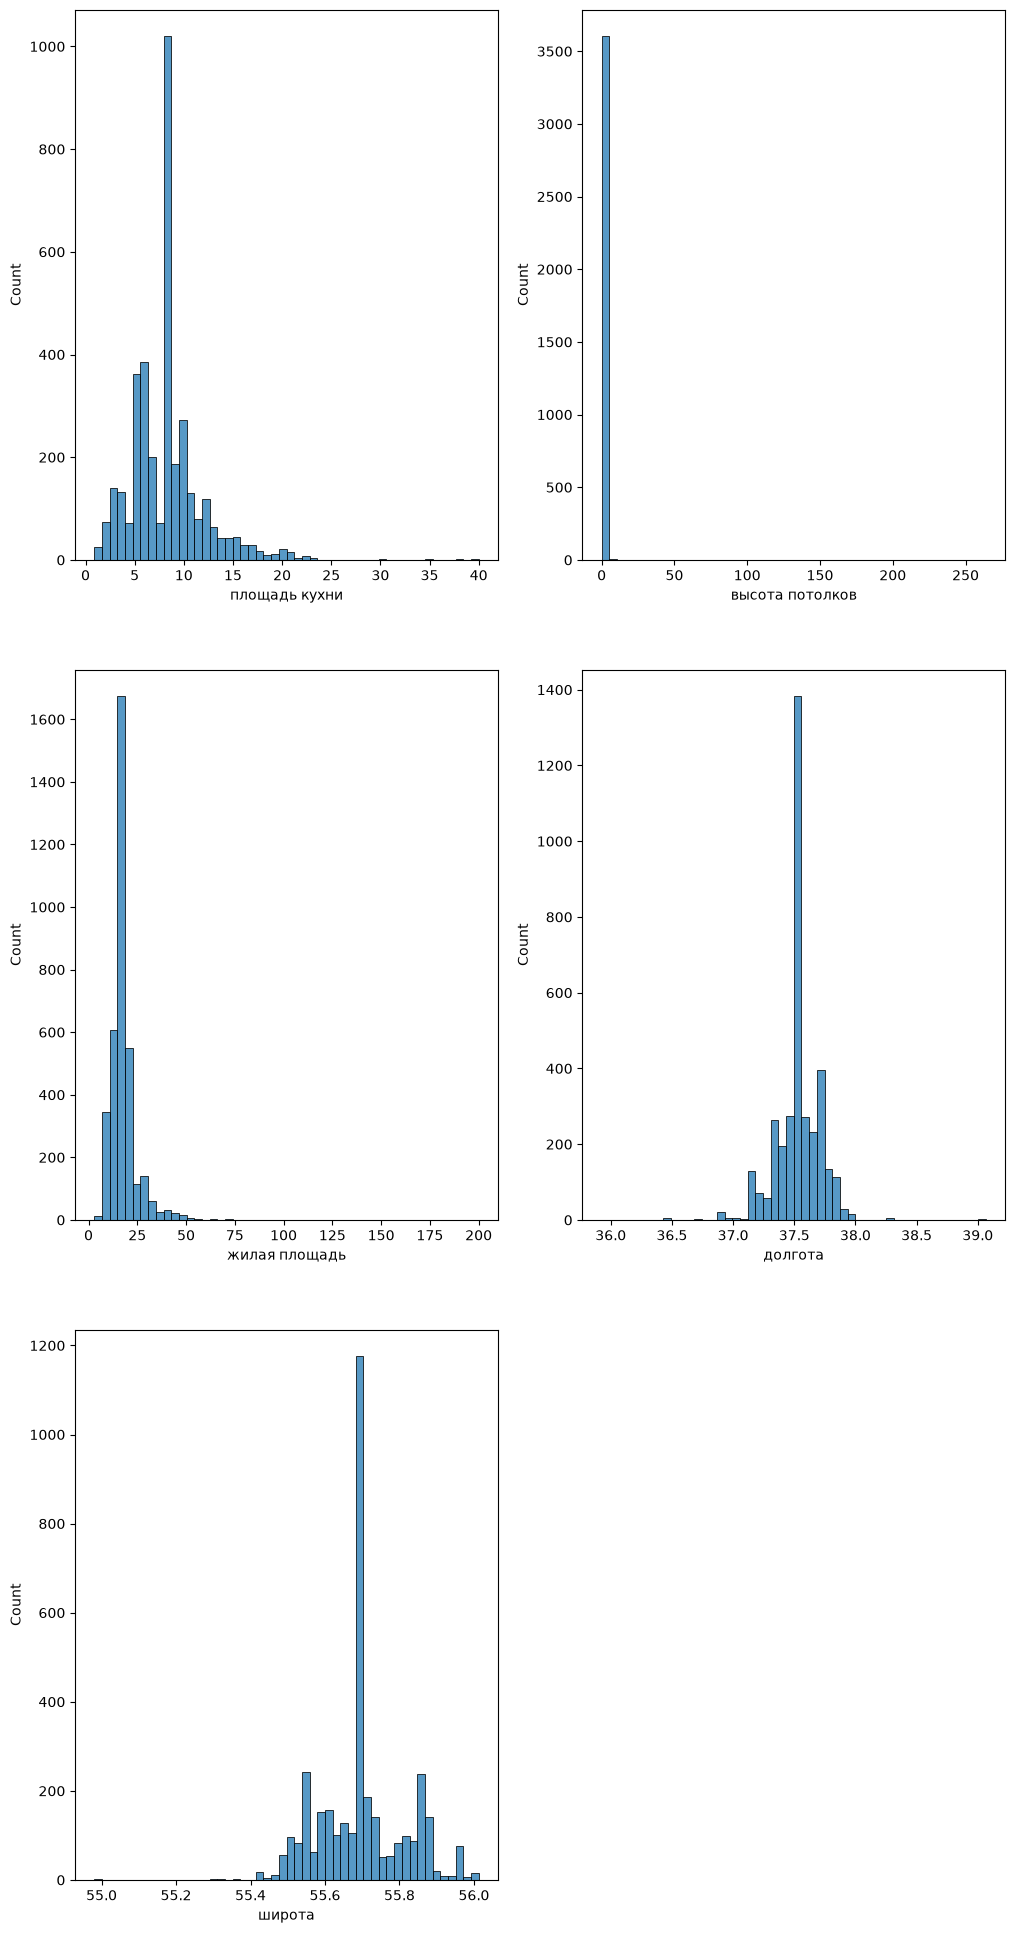

In [75]:
plt.figure(figsize=(12, 50))

for i, clm in enumerate(contin_clmns):
    sub_plt = plt.subplot(6,2,i + 1)
    sns.histplot(df[clm], kde=False, bins = 50)

In [54]:
for clm_name in data_train.select_dtypes(include="number").columns[:-2]:
    Q1 = df[clm_name].quantile(0.25)
    Q3 = df[clm_name].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 4 * IQR
    upper_bound = Q3 + 4 * IQR

    data_train = data_train[data_train[clm_name] > lower_bound]
    data_train = data_train[data_train[clm_name] < upper_bound]

In [55]:
data_train.reset_index(inplace=True, drop=True)

In [56]:
category_clmns = ["этаж", "тип жилья", "санузел", "количество лифтов", "тип дома"]
contin_clmns = ["площадь кухни", "высота потолков", "жилая площадь", "стоимость", "общая площадь", "долгота", "широта"]

one_hot_encoder = skl.preprocessing.OneHotEncoder(drop="first", sparse_output=False)
std_scaler = skl.preprocessing.StandardScaler()

# for clm in contin_clmns:
#     df[clm] = std_scaler.fit_transform(df[clm].to_numpy().reshape(-1, 1))

In [57]:
std_scaler.fit(data_train[contin_clmns].to_numpy())
data_train[contin_clmns] = std_scaler.transform(data_train[contin_clmns].to_numpy())
data_test[contin_clmns] = std_scaler.transform(data_test[contin_clmns].to_numpy())


In [59]:
data_train.reset_index(inplace=True, drop=True)
data_test.reset_index(inplace=True, drop=True)

one_hot_encoder.fit(data_train[category_clmns].to_numpy())

encoder_data = one_hot_encoder.transform(data_train[category_clmns].to_numpy())
data_train.drop(category_clmns, axis=1, inplace=True)
new_clmns_name = one_hot_encoder.get_feature_names_out(input_features=category_clmns)

encoder_df = pd.DataFrame(encoder_data, columns=new_clmns_name)
data_train = pd.concat([data_train, encoder_df], axis=1)

encoder_data = one_hot_encoder.transform(data_test[category_clmns].to_numpy())
data_test.drop(category_clmns, axis=1, inplace=True)
new_clmns_name = one_hot_encoder.get_feature_names_out(input_features=category_clmns)

encoder_df = pd.DataFrame(encoder_data, columns=new_clmns_name)
data_test = pd.concat([data_test, encoder_df], axis=1)


In [61]:
data_train

,стоимость,общая площадь,площадь кухни,высота потолков,жилая площадь,долгота,широта,раздельный_санузел,грузовой_лифт,этаж_выше - среднего,этаж_ниже - среднего,этаж_нижние,этаж_средние,тип жилья_вторичка / апартаменты,тип жилья_вторичка / пентхаус,тип жилья_новостройка,тип жилья_новостройка / апартаменты,тип жилья_новостройка / пентхаус,санузел_2_3_санузла,санузел_больше 3 санузла,количество лифтов_немного_лифтов,количество лифтов_среднее_кол_лифтов,тип дома_газобетонный блок,тип дома_кирпичный,тип дома_монолитно-кирпичный,тип дома_монолитный,тип дома_панельный,тип дома_сталинский,тип дома_старый фонд
0,1.752157,0.904398,0.769720,3.013259,1.248818,1.468156,0.793042,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-0.916580,-1.107426,-1.547847,0.323281,-0.717702,-0.272679,0.643564,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-1.218942,-0.894681,0.003087,0.064506,0.005285,-1.744188,-1.110909,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.136538,0.488159,-1.002537,0.750261,0.966798,-0.660080,1.220634,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1.963827,1.468634,0.003087,-0.103700,2.011035,-0.000232,-0.001841,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44769,1.022619,-0.538565,-0.184572,2.031203,-0.260372,-0.129764,0.142063,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
44770,-0.614373,-0.126951,0.923089,-0.786869,-0.725324,-0.000232,-0.001841,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
44771,-1.222770,-1.014928,-1.207029,-1.213850,-0.412815,2.022187,-0.752756,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
44772,1.447882,0.603781,-0.866210,0.323281,1.416506,0.061808,0.596987,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [62]:
# x_data = df.iloc[:, 1:]
# y_data = df.iloc[:, 0]

x_train, x_test, y_train, y_test = data_train.iloc[:, 1:], data_test.iloc[:, 1:], data_train.iloc[:, 0], data_test.iloc[:, 0]
# x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.3, random_state=42)


# corr_matrix = x_data.corr(method="spearman")

# upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
# to_drop = [column for column in upper_tri.columns if any(upper_tri[column] >= 0.3)]

# df.drop(to_drop, axis=1, inplace=True)

In [150]:
rand_forest = RandomForestRegressor(n_estimators=100, max_depth=13)

rand_forest.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",13
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number

In [151]:
y_predict = rand_forest.predict(x_test)

In [152]:
skl.metrics.r2_score(y_test, y_predict)

0.8224700598018475

In [63]:
train_lgbm = lgbm.Dataset(x_train.to_numpy(), label=y_train.to_numpy())

learning_rate = np.linspace(0.05, 0.7, 3)
feature_frac = [0.7, 0.8]
num_iteration = np.linspace(100, 1000, 3, dtype=int)
best_model = None
best_score = 0

for l in learning_rate:
    for f in feature_frac:
        for n in num_iteration:
            param = {'objective': 'regression', "metric": ["l2"], "learning_rate": l, "feature_fraction": f, "num_iterations": n, "verbosity": -1}
            model_lgbm = lgbm.train(params=param, train_set=train_lgbm)
            pred_lgbm = model_lgbm.predict(x_test)
            
            r2_lgbm = skl.metrics.r2_score(y_test, pred_lgbm)
            if r2_lgbm > best_score:
                best_score = r2_lgbm
                best_model = model_lgbm
                print(best_score)
print(best_score)

0.7930260084071128
0.8527325849395095
0.8635509081685371
0.8647286972877727
0.8665090557508385
0.8697101479674727
0.8705517392834218
0.8705517392834218
